# Normalization
- Each step of quality control such as removing low-quality cells, ambient RNA contamination and doublet detection adds a degree of variability to the measured count depth for identical cells, so the difference in gene expression between cells in the count data might simply be due to sampling effects.
- Aims to adjust the raw counts for variable sampling effects by scaling the observable variance to a specified range.
- Three normalization techniques would be considered here:
    - `Shifted logarithm transformation`: Beneficial for stabilizing variance for subsequent dimensionality reduction and identification of differentially expressed genes.
    - `scran normalization`: Used for batch correction tasks.
    - `Analytic approximation of Pearson resisuals`: Well suited for selecting biologically variable genes and identification of rare cell types.

In [1]:
import logging

import lamindb as ln
import numpy as np
import rpy2.rinterface_lib.callbacks as rcb
import rpy2.robjects as ro
import scanpy as sc
import seaborn as sns
from matplotlib import pyplot as plt
from rpy2.robjects import numpy2ri, pandas2ri
from rpy2.robjects.conversion import localconverter
from scipy.sparse import issparse

# Suppress verbose logging from Scanpy
sc.settings.verbosity = 0

# Set figure parameters for clean, minimal plots
sc.set_figure_params(dpi=80, facecolor="white", frameon=False)

rcb.logger.setLevel(logging.ERROR)

%load_ext rpy2.ipython

ln.connect("theislab/sc-best-practices")

→ connected lamindb: anonymous/intermediate_data
! re-setting django: avoid this by clearing the default instance on the command line via: lamin disconnect
→ connected lamindb: theislab/sc-best-practices
! connected in read-only mode, please use ln.DB("theislab/sc-best-practices") instead


In [2]:
af = ln.Artifact.connect("theislab/sc-best-practices").get(
    key="preprocessing_visualization/s4d8_quality_control.h5ad", is_latest=True
)
adata = af.load()
adata

AnnData object with n_obs × n_vars = 15998 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: 'counts', 'soupX_counts', None (.X)

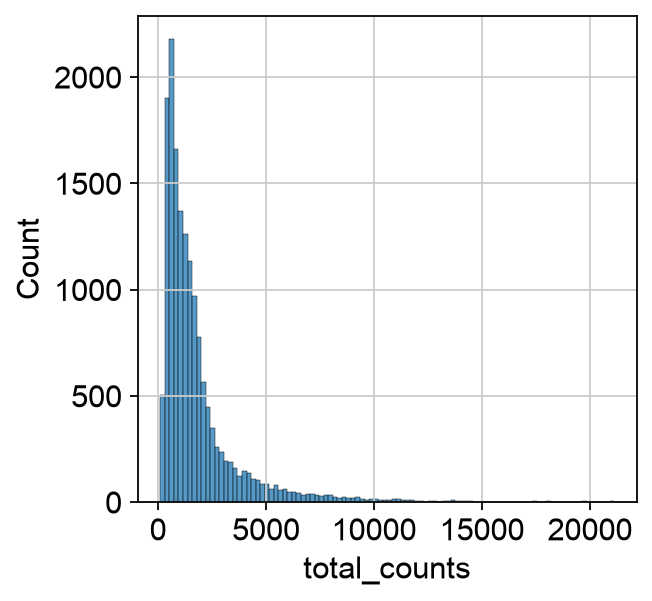

In [3]:
# Distribution of raw counts
p1 = sns.histplot(adata.obs["total_counts"], bins = 100, kde = False)

# Shifted Logarithm
- Based on the delta method.
- Applies a non-linear function to the raw counts and aims to make the variances across the dataset more similar.

In [4]:
scales_counts = sc.pp.normalize_total(adata, target_sum=None, inplace=False)
# log1p transform
adata.layers["log1p_norm"] = sc.pp.log1p(scales_counts["X"], copy=True)

In [5]:
adata

AnnData object with n_obs × n_vars = 15998 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: 'counts', 'soupX_counts', None (.X), 'log1p_norm'

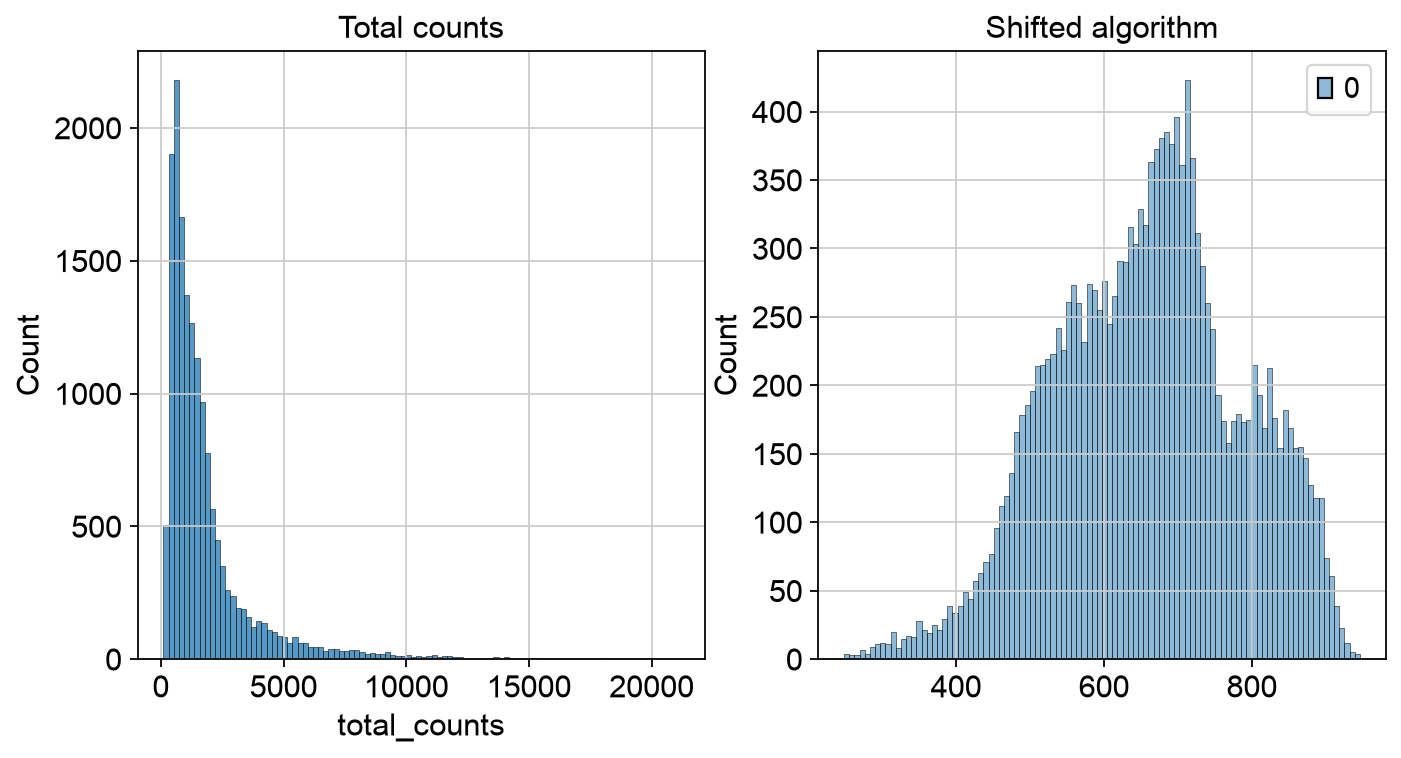

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10,5))

p1 = sns.histplot(adata.obs["total_counts"], bins=100, kde=False, ax=axes[0])
axes[0].set_title("Total counts")

p2 = sns.histplot(adata.layers["log1p_norm"].sum(1), bins=100, kde=False, ax=axes[1])
axes[1].set_title("Shifted algorithm")

plt.show()

# Scran normalization
- Scran's pooling-based size factor estimation method is also based on the delta method.
- The only difference from shifted logarithm is it leverages a deconvolution approach to estimate the size factors based on a linear regression over genes for pools of cells.
- This aims to better account for differences in count depths across all cells present in the dataset.

In [7]:
from scipy.sparse import csr_matrix

In [8]:
%%R
library(scran)
library(BiocParallel)

Loading required package: SingleCellExperiment
Loading required package: SummarizedExperiment
Loading required package: MatrixGenerics
Loading required package: matrixStats

Attaching package: ‘MatrixGenerics’

The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollapse, rowCounts, rowCummaxs, rowCummins, rowCumprods,
    rowCumsums, rowDiffs, rowIQRDiffs, rowIQRs, rowLogSumExps,
    rowMadDiffs, rowMads, rowMaxs, rowMeans2, rowMedians, rowMins,
    rowOr

In [9]:
# scran requires a coarse clustering input to improve size factor estimation performance
adata_pp = adata.copy()
sc.pp.normalize_total(adata_pp)
sc.pp.log1p(adata_pp)
sc.pp.pca(adata_pp, n_comps=15)
sc.pp.neighbors(adata_pp)
sc.tl.leiden(adata_pp, key_added="groups", flavor="igraph", n_iterations=2, directed=False)

In [10]:
adata_pp

AnnData object with n_obs × n_vars = 15998 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class', 'groups'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'log1p', 'pca', 'neighbors', 'groups'
    obsm: 'X_pca'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: 'counts', 'soupX_counts', None (.X), 'log1p_norm'

In [11]:
# scran's computeSumFactors requires raw counts (not normalized or log-transformed).
# adata_pp.X is log-normalized and used only for clustering, so we pass the original counts here instead.
data_mat = adata.layers["counts"].T
# convert to CSC if possible. See https://github.com/MarioniLab/scran/issues/70
if issparse(data_mat):
    if data_mat.nnz > 2**31 - 1: # nnz is non-zero elements
        data_mat = data_mat.tocoo() # coordinate format
    else:
        data_mat = data_mat.tocsc() # Compressed Sparse Column format
    # Convert sparse matrix to dense numpy array
    data_mat = data_mat.toarray()

with localconverter(ro.default_converter + numpy2ri.converter):
    ro.globalenv["data_mat"] = data_mat

with localconverter(ro.default_converter + pandas2ri.converter):
    ro.globalenv["input_groups"] = adata_pp.obs["groups"]

In [12]:
%%R -o size_factors
# Compute size factors using the coarse clusters from the preceding cells.

sce <- SingleCellExperiment(list(counts = data_mat))
sce <- computeSumFactors(
    sce,
    clusters = as.character(input_groups),
    min.mean = 0.1,
    BPPARAM = MulticoreParam()
)
size_factors <- sizeFactors(sce)

In [13]:
adata.obs["size_factors"] = size_factors
scran = adata.X / adata.obs["size_factors"].values[:, None] # dividing the raw expression values by their respective size factors
scran_logged = np.log1p(scran)
adata.layers["scran_normalization"] = csr_matrix(scran_logged)

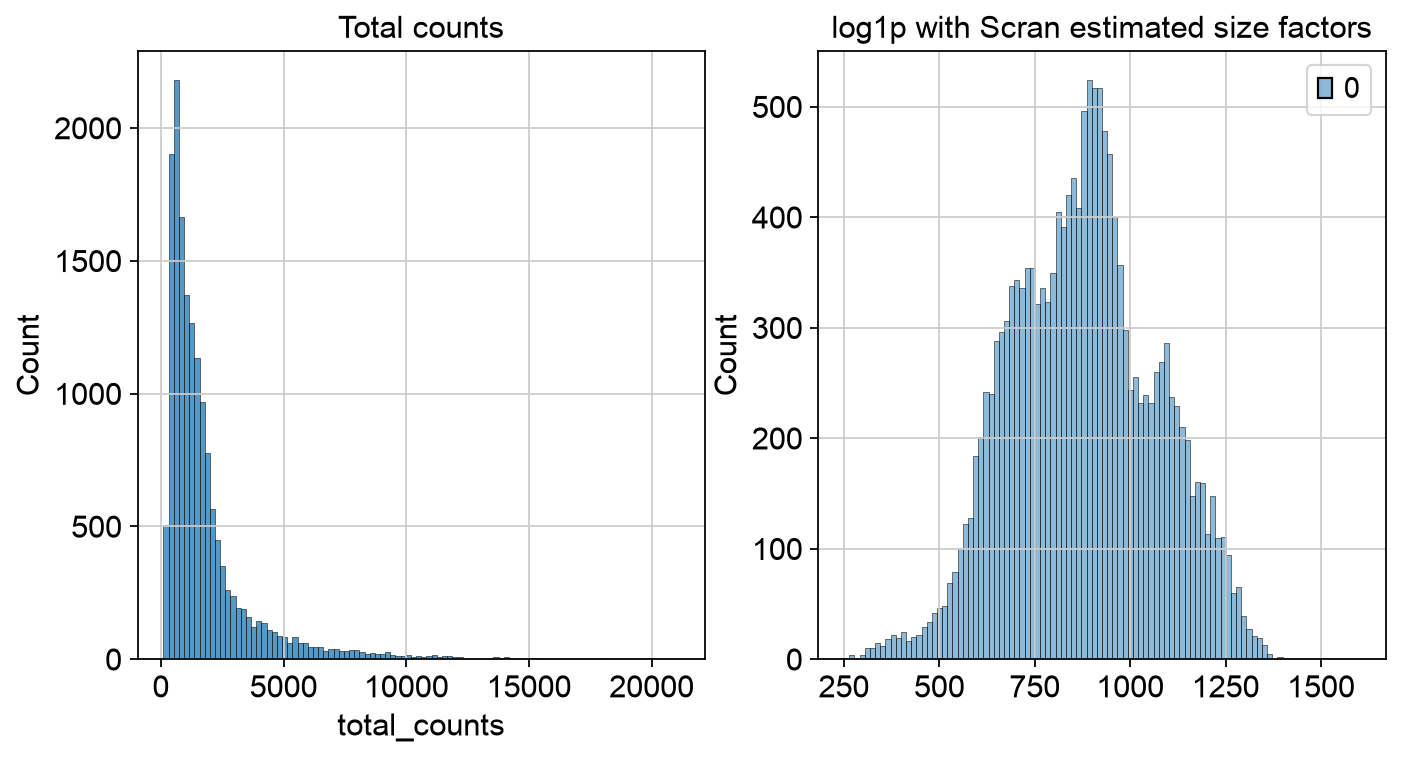

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
p1 = sns.histplot(adata.obs["total_counts"], bins=100, kde=False, ax=axes[0])
axes[0].set_title("Total counts")
p2 = sns.histplot(adata.layers["scran_normalization"].sum(1), bins=100, kde=False, ax=axes[1])
axes[1].set_title("log1p with Scran estimated size factors")
plt.show()

# Analytic Pearson residuals
- Cell-to-cell variation in scRNA-seq data might be confounded by biological heterogeneity with technical effects.
- Utilizes Pearson residuals from regularized negative binomial regression to calculate a model of technical noise in the data. It also adds count depth as a covariate in a generalized linear model.
- This method removes the impact of sampling effects while preserving cell heterogeneity in the dataset.
- The output of the method is normalized values that can be positive or negative.
    - Negative residuals for a cell and gene indicate that fewer counts are observed than expected compared to the gene's average expression and cellular sequencing depth.
    - Positive residuals for a cell and gene indicate that more counts are observed than expected.

In [15]:
analytic_pearson = sc.experimental.pp.normalize_pearson_residuals(adata, inplace=False)
adata.layers["analytic_pearson_residuals"] = csr_matrix(analytic_pearson["X"])

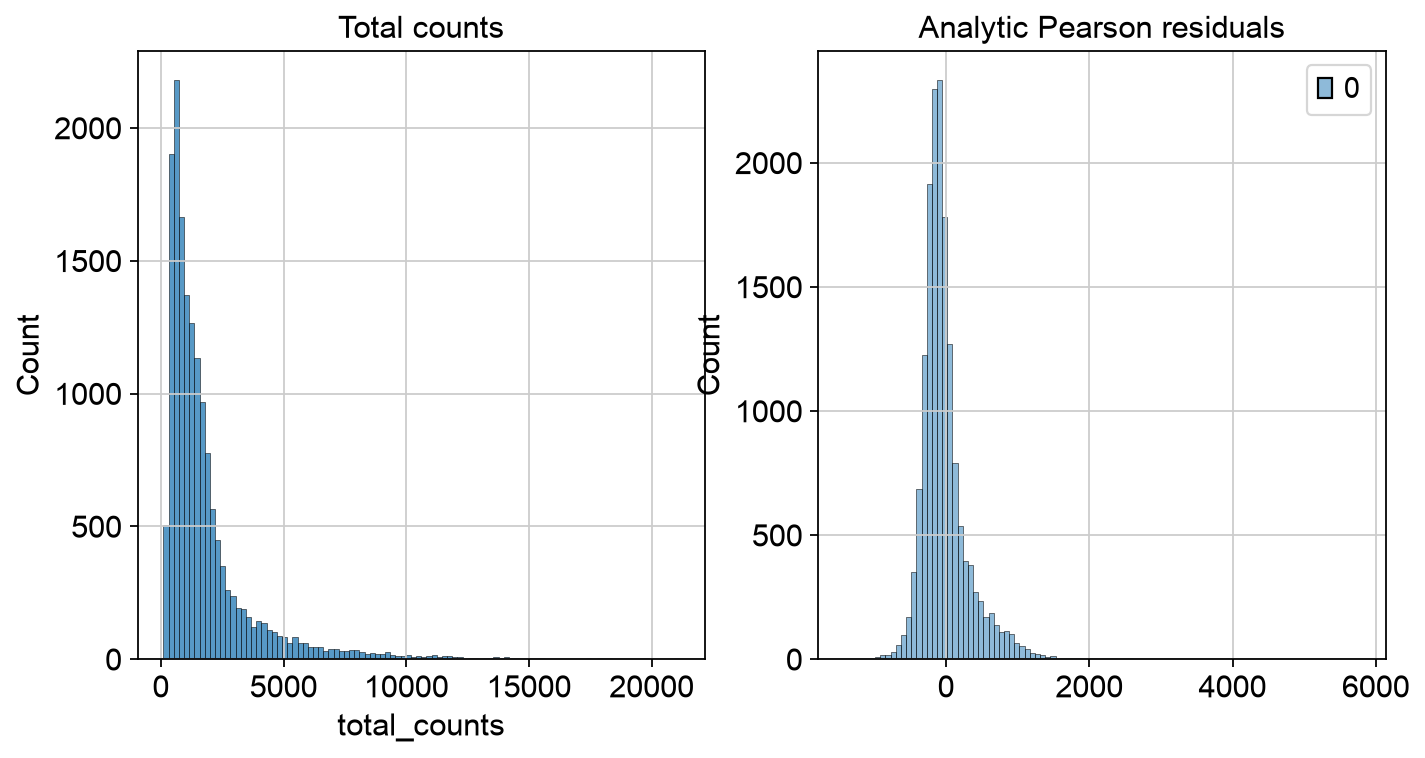

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
p1 = sns.histplot(adata.obs["total_counts"], bins=100, kde=False, ax=axes[0])
axes[0].set_title("Total counts")
p2 = sns.histplot(adata.layers["analytic_pearson_residuals"].sum(1), bins=100, kde=False, ax=axes[1])
axes[1].set_title("Analytic Pearson residuals")
plt.show()

In [17]:
adata

AnnData object with n_obs × n_vars = 15998 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class', 'size_factors'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: 'counts', 'soupX_counts', None (.X), 'log1p_norm', 'scran_normalization', 'analytic_pearson_residuals'

In [18]:
from pathlib import Path

output_dir = Path("../intermediate_data")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "normalization.h5ad"

adata.write_h5ad(output_path, compression="gzip")
print(f"Saved normalized dataset to: {output_path.resolve()}")

Saved normalized dataset to: /Users/ankitmukherjee/Bioinformatics/single_cell_analysis/scverse/05_scRNA_analysis/intermediate_data/normalization.h5ad
